In [1]:
import csv
import json
import random
import shutil
import time
import zipfile
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

datapath = "/kaggle/working/data"
outputpath = Path("/kaggle/working/bcd_outputs")
evaluationpath = outputpath / "evaluation"

batchsize = 32
trainingepochs = 30
seedlist = [0, 1]

outputpath.mkdir(parents=True, exist_ok=True)
evaluationpath.mkdir(parents=True, exist_ok=True)

for modelname in ["modelb", "modelc", "modeld"]:
    (outputpath / modelname).mkdir(exist_ok=True)

print("Device:", device)
print("PyTorch:", torch.__version__)


Device: cuda
PyTorch: 2.11.0+cu128


In [3]:
class convlstmcell(nn.Module):
    def __init__(self, inputchannels, hiddenchannels, dilation=1):
        super().__init__()

        self.gateconvolution = nn.Conv2d(
            inputchannels + hiddenchannels,
            4 * hiddenchannels,
            kernel_size=3,
            padding=dilation,
            dilation=dilation,
            bias=True,
        )

    def forward(self, inputs, hiddenstate, cellstate):
        gates = self.gateconvolution(
            torch.cat((inputs, hiddenstate), dim=1)
        )

        inputgate, forgetgate, outputgate, candidate = torch.chunk(
            gates, 4, dim=1
        )

        cellstate = (
            torch.sigmoid(forgetgate) * cellstate
            + torch.sigmoid(inputgate) * torch.tanh(candidate)
        )

        hiddenstate = torch.sigmoid(outputgate) * torch.tanh(cellstate)

        return hiddenstate, cellstate


class modela(nn.Module):
    def __init__(self, dilation=1):
        super().__init__()

        self.firstcell = convlstmcell(16, 64, dilation)
        self.secondcell = convlstmcell(64, 64, dilation)
        self.outputlayer = nn.Conv2d(64, 16, kernel_size=1, bias=True)

    def forward(self, inputframes):
        batchcount = inputframes.shape[0]

        hiddenone = inputframes.new_zeros(batchcount, 64, 16, 16)
        cellone = inputframes.new_zeros(batchcount, 64, 16, 16)

        hiddentwo = inputframes.new_zeros(batchcount, 64, 16, 16)
        celltwo = inputframes.new_zeros(batchcount, 64, 16, 16)

        predictions = []
        previousprediction = None

        for step in range(9):
            if step < 5:
                currentframe = inputframes[:, step]
            else:
                currentframe = previousprediction

            foldedframe = F.pixel_unshuffle(currentframe, 4)

            hiddenone, cellone = self.firstcell(
                foldedframe, hiddenone, cellone
            )

            hiddentwo, celltwo = self.secondcell(
                hiddenone, hiddentwo, celltwo
            )

            previousprediction = torch.sigmoid(
                F.pixel_shuffle(self.outputlayer(hiddentwo), 4)
            )

            if step >= 4:
                predictions.append(previousprediction)

        return torch.stack(predictions, dim=1)


class modeld(modela):
    def __init__(self):
        super().__init__(dilation=2)


def countparameters(model):
    total = 0

    for parameter in model.parameters():
        if parameter.requires_grad:
            total += parameter.numel()

    return total


modelacheck = modela()
modeldcheck = modeld()

print("Model A parameters:", countparameters(modelacheck))
print("Model D parameters:", countparameters(modeldcheck))

assert countparameters(modelacheck) == 480784
assert countparameters(modeldcheck) <= 721176

print("Model A reach: 8 original pixels")
print("Model D reach: 16 original pixels")
print("Architecture valid")

del modelacheck, modeldcheck

Model A parameters: 480784
Model D parameters: 480784
Model A reach: 8 original pixels
Model D reach: 16 original pixels
Architecture valid


In [5]:
def loadvideos():
    rawfiles = sorted(
        Path("/kaggle/input").rglob("mnist_test_seq.npy")
    )

    if rawfiles:
        print("Loading attached dataset:", rawfiles[0])

        data = np.load(rawfiles[0])

        if data.shape == (20, 10000, 64, 64):
            data = np.ascontiguousarray(
                data.transpose(1, 0, 2, 3)
            )

        rawvideos = torch.from_numpy(data)

    else:
        print("Loading MNIST")

        dataset = torchvision.datasets.MovingMNIST(
            root=datapath,
            split=None,
            download=True,
        )

        rawvideos = torch.as_tensor(dataset.data)

    if rawvideos.ndim == 4:
        rawvideos = rawvideos.unsqueeze(2)

    if tuple(rawvideos.shape) != (10000, 20, 1, 64, 64):
        raise RuntimeError(f"Invalid dataset shape: {rawvideos.shape}")

    rawvideos = rawvideos.contiguous()

    scaledata = (
        not rawvideos.is_floating_point()
        or rawvideos.max().item() > 1.0
    )

    return rawvideos, scaledata


def convertvideos(videos, scaledata):
    videos = videos.to(device=device, dtype=torch.float32)

    if scaledata:
        videos = videos / 255.0

    return videos


rawvideos, scaledata = loadvideos()

trainvideos = rawvideos[:8000]
validationvideos = rawvideos[8000:9000]
testvideos = rawvideos[9000:10000]

print("Training:", len(trainvideos))
print("Validation:", len(validationvideos))
print("Test:", len(testvideos))
print("Scaled by 225")

Loading attached dataset: /kaggle/input/notebooks/kangerz22/modela-training/data/MovingMNIST/mnist_test_seq.npy
Training: 8000
Validation: 1000
Test: 1000
Scaled by 225


In [6]:
def applysymmetry(frames, symmetry):
    frames = torch.rot90(
        frames,
        k=symmetry % 4,
        dims=(-2, -1),
    )

    if symmetry >= 4:
        frames = torch.flip(frames, dims=(-1,))

    return frames


def makewindows(videos, modeltype):
    batchcount = videos.shape[0]

    if modeltype == "b":
        speeds = torch.ones(
            batchcount,
            dtype=torch.long,
            device=device,
        )

        starts = torch.randint(
            0, 11, (batchcount,), device=device
        )

    elif modeltype in ("c", "d"):
        speeds = torch.randint(
            1, 4, (batchcount,), device=device
        )

        maxstarts = torch.where(
            speeds == 1,
            14,
            torch.where(speeds == 2, 8, 2),
        )

        starts = (
            torch.rand(batchcount, device=device) * maxstarts
        ).long()

    else:
        raise ValueError(f"Invalid model: {modeltype}")

    batchpositions = torch.arange(
        batchcount, device=device
    )[:, None]

    inputindices = (
        starts[:, None]
        + speeds[:, None]
        * torch.arange(5, device=device)[None, :]
    )

    targetindices = (
        starts[:, None]
        + speeds[:, None]
        * torch.arange(5, 10, device=device)[None, :]
    )

    validtargets = targetindices < 20

    inputframes = videos[
        batchpositions, inputindices
    ]

    targetframes = videos[
        batchpositions, targetindices.clamp(max=19)
    ]

    if modeltype == "b":
        transformations = torch.randint(
            0, 8, (batchcount,), device=device
        )

        for symmetry in range(8):
            chosen = transformations == symmetry

            if chosen.any():
                inputframes[chosen] = applysymmetry(
                    inputframes[chosen], symmetry
                )

                targetframes[chosen] = applysymmetry(
                    targetframes[chosen], symmetry
                )

    return inputframes, targetframes, validtargets

In [7]:
for speed, maxstart in [(1, 14), (2, 8), (3, 2)]:
    for start in range(maxstart):
        inputindices = [
            start + step * speed
            for step in range(5)
        ]

        targetindices = [
            start + step * speed
            for step in range(5, 10)
            if start + step * speed < 20
        ]

        assert max(inputindices) < 20
        assert len(targetindices) >= 2

print("Window index valid")

samplevideos = convertvideos(
    trainvideos[:32], scaledata
)

for modeltype in ["b", "c", "d"]:
    inputs, targets, valid = makewindows(
        samplevideos, modeltype
    )

    assert inputs.shape == (32, 5, 1, 64, 64)
    assert targets.shape == (32, 5, 1, 64, 64)
    assert valid.shape == (32, 5)
    assert torch.all(valid.sum(dim=1) >= 2)

    print(
        modeltype.upper(),
        "valid targets:",
        valid.sum(dim=1).unique().tolist(),
    )

with torch.no_grad():
    for modeltype in ["b", "d"]:
        model = modeld() if modeltype == "d" else modela()
        model = model.to(device)

        predictions = model(samplevideos[:2, :5])

        assert predictions.shape == (2, 5, 1, 64, 64)
        assert torch.isfinite(predictions).all()

        print(modeltype.upper(), "forward pass correct")

        del model

del samplevideos

if device.type == "cuda":
    torch.cuda.empty_cache()

print("initial checks valid")

Window index valid
B valid targets: [5]
C valid targets: [2, 3, 4, 5]
D valid targets: [2, 3, 4, 5]
B forward pass correct
D forward pass correct
initial checks valid


In [9]:
def setseed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def trainmodel(modeltype, seed):
    setseed(seed)

    modelname = "model" + modeltype
    modelpath = outputpath / modelname

    if modeltype == "d":
        model = modeld().to(device)
    else:
        model = modela().to(device)

    parametercount = countparameters(model)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    epochseconds = []
    epochlosses = []

    print(
        f"\nModel {modeltype.upper()} | "
        f"seed {seed} | parameters {parametercount}"
    )

    for epoch in range(trainingepochs):
        model.train()

        videoorder = torch.randperm(
            len(trainvideos)
        )

        if device.type == "cuda":
            torch.cuda.synchronize()

        epochstart = time.perf_counter()
        totalloss = 0.0

        for batchstart in range(
            0, len(trainvideos), batchsize
        ):
            batchindices = videoorder[
                batchstart:batchstart + batchsize
            ]

            batchvideos = convertvideos(
                trainvideos[batchindices],
                scaledata,
            )

            inputs, targets, valid = makewindows(
                batchvideos, modeltype
            )

            predictions = model(inputs)

            lossperframe = (
                (predictions - targets)
                .square()
                .mean(dim=(2, 3, 4))
            )

            losspervideo = (
                (lossperframe * valid).sum(dim=1)
                / valid.sum(dim=1)
            )

            loss = losspervideo.mean()

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            totalloss += (
                loss.detach().item() * len(batchindices)
            )

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - epochstart
        epochloss = totalloss / len(trainvideos)

        epochseconds.append(elapsed)
        epochlosses.append(epochloss)

        print(
            f"Epoch {epoch + 1:02d}/{trainingepochs} | "
            f"loss {epochloss:.6f} | "
            f"{elapsed:.2f}s"
        )

    checkpointfile = (
        modelpath / f"{modelname}seed{seed}.pt"
    )

    savedstate = {
        name: value.detach().cpu()
        for name, value in model.state_dict().items()
    }

    record = {
        "model": modelname,
        "seed": seed,
        "epochs": trainingepochs,
        "parameters": parametercount,
        "meanepochseconds": float(np.mean(epochseconds)),
        "epochseconds": epochseconds,
        "epochlosses": epochlosses,
        "checkpoint": str(checkpointfile),
    }

    torch.save(
        {"modelstate": savedstate, **record},
        checkpointfile,
    )

    logfile = modelpath / "traininglog.json"

    if logfile.exists():
        with open(logfile, "r") as file:
            records = json.load(file)
    else:
        records = []

    records = [
        entry for entry in records
        if entry["seed"] != seed
    ]

    records.append(record)
    records.sort(key=lambda entry: entry["seed"])

    with open(logfile, "w") as file:
        json.dump(records, file, indent=2)

    print("Saved:", checkpointfile)

    del model, optimizer

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return record

In [10]:
for seed in seedlist:
    checkpointfile = (
        outputpath / "modelb" / f"modelbseed{seed}.pt"
    )

    if checkpointfile.exists():
        print("Already trained:", checkpointfile)
        continue

    trainmodel("b", seed)

print("Model B training done")


Model B | seed 0 | parameters 480784
Epoch 01/30 | loss 0.046066 | 11.64s
Epoch 02/30 | loss 0.039859 | 11.03s
Epoch 03/30 | loss 0.038790 | 11.15s
Epoch 04/30 | loss 0.037082 | 11.27s
Epoch 05/30 | loss 0.035186 | 11.36s
Epoch 06/30 | loss 0.033399 | 11.46s
Epoch 07/30 | loss 0.031978 | 11.59s
Epoch 08/30 | loss 0.030899 | 11.73s
Epoch 09/30 | loss 0.030175 | 11.76s
Epoch 10/30 | loss 0.029747 | 11.68s
Epoch 11/30 | loss 0.029346 | 11.61s
Epoch 12/30 | loss 0.029051 | 11.53s
Epoch 13/30 | loss 0.028557 | 11.57s
Epoch 14/30 | loss 0.028146 | 11.57s
Epoch 15/30 | loss 0.027790 | 11.59s
Epoch 16/30 | loss 0.027225 | 11.65s
Epoch 17/30 | loss 0.026800 | 11.66s
Epoch 18/30 | loss 0.026366 | 11.71s
Epoch 19/30 | loss 0.025829 | 11.73s
Epoch 20/30 | loss 0.025285 | 11.72s
Epoch 21/30 | loss 0.024836 | 11.69s
Epoch 22/30 | loss 0.024384 | 11.71s
Epoch 23/30 | loss 0.024083 | 11.70s
Epoch 24/30 | loss 0.023670 | 11.69s
Epoch 25/30 | loss 0.023293 | 11.71s
Epoch 26/30 | loss 0.022943 | 11.71s


In [11]:
for seed in seedlist:
    checkpointfile = (
        outputpath / "modelc" / f"modelcseed{seed}.pt"
    )

    if checkpointfile.exists():
        print("Already trained:", checkpointfile)
        continue

    trainmodel("c", seed)

print("Model C training done")


Model C | seed 0 | parameters 480784
Epoch 01/30 | loss 0.046566 | 10.89s
Epoch 02/30 | loss 0.039831 | 11.01s
Epoch 03/30 | loss 0.039200 | 11.14s
Epoch 04/30 | loss 0.038489 | 11.08s
Epoch 05/30 | loss 0.037718 | 10.98s
Epoch 06/30 | loss 0.036772 | 10.90s
Epoch 07/30 | loss 0.036135 | 10.88s
Epoch 08/30 | loss 0.035515 | 10.88s
Epoch 09/30 | loss 0.035039 | 10.93s
Epoch 10/30 | loss 0.034671 | 10.97s
Epoch 11/30 | loss 0.034273 | 11.01s
Epoch 12/30 | loss 0.033951 | 10.97s
Epoch 13/30 | loss 0.033627 | 10.98s
Epoch 14/30 | loss 0.033355 | 10.99s
Epoch 15/30 | loss 0.032998 | 10.96s
Epoch 16/30 | loss 0.032807 | 10.97s
Epoch 17/30 | loss 0.032678 | 10.96s
Epoch 18/30 | loss 0.032506 | 10.99s
Epoch 19/30 | loss 0.032353 | 10.97s
Epoch 20/30 | loss 0.032031 | 11.02s
Epoch 21/30 | loss 0.031950 | 11.01s
Epoch 22/30 | loss 0.031811 | 10.99s
Epoch 23/30 | loss 0.031746 | 10.98s
Epoch 24/30 | loss 0.031566 | 10.99s
Epoch 25/30 | loss 0.031486 | 10.96s
Epoch 26/30 | loss 0.031410 | 10.99s


In [12]:
for seed in seedlist:
    checkpointfile = (
        outputpath / "modeld" / f"modeldseed{seed}.pt"
    )

    if checkpointfile.exists():
        print("Already trained:", checkpointfile)
        continue

    trainmodel("d", seed)

print("Model D training done")


Model D | seed 0 | parameters 480784
Epoch 01/30 | loss 0.046591 | 18.72s
Epoch 02/30 | loss 0.039969 | 18.93s
Epoch 03/30 | loss 0.039836 | 18.62s
Epoch 04/30 | loss 0.039074 | 18.41s
Epoch 05/30 | loss 0.037745 | 18.40s
Epoch 06/30 | loss 0.036986 | 18.56s
Epoch 07/30 | loss 0.036414 | 18.68s
Epoch 08/30 | loss 0.035861 | 18.65s
Epoch 09/30 | loss 0.035266 | 18.63s
Epoch 10/30 | loss 0.034613 | 18.67s
Epoch 11/30 | loss 0.033958 | 18.62s
Epoch 12/30 | loss 0.033542 | 18.60s
Epoch 13/30 | loss 0.033090 | 18.60s
Epoch 14/30 | loss 0.032790 | 18.60s
Epoch 15/30 | loss 0.032381 | 18.60s
Epoch 16/30 | loss 0.032094 | 18.61s
Epoch 17/30 | loss 0.031860 | 18.60s
Epoch 18/30 | loss 0.031634 | 18.62s
Epoch 19/30 | loss 0.031425 | 18.60s
Epoch 20/30 | loss 0.031077 | 18.61s
Epoch 21/30 | loss 0.030919 | 18.62s
Epoch 22/30 | loss 0.030698 | 18.60s
Epoch 23/30 | loss 0.030596 | 18.61s
Epoch 24/30 | loss 0.030432 | 18.61s
Epoch 25/30 | loss 0.030336 | 18.61s
Epoch 26/30 | loss 0.030236 | 18.61s


In [13]:
def evaluatemodel(model):
    model.eval()

    totals = {
        "e5": 0.0,
        "cm": 0.0,
        "em": 0.0,
        "cr": 0.0,
        "er": 0.0,
        "e2_1x": 0.0,
        "e2_2x": 0.0,
        "e2_3x": 0.0,
    }

    inferenceseconds = 0.0
    testedvideos = 0

    with torch.no_grad():
        for batchstart in range(
            0, len(testvideos), batchsize
        ):
            batchvideos = convertvideos(
                testvideos[batchstart:batchstart + batchsize],
                scaledata,
            )

            inputframes = batchvideos[:, :5]
            targetframes = batchvideos[:, 5:10]

            if device.type == "cuda":
                torch.cuda.synchronize()

            inferencestart = time.perf_counter()

            predictions = model(inputframes)

            if device.type == "cuda":
                torch.cuda.synchronize()

            inferenceseconds += (
                time.perf_counter() - inferencestart
            )

            errors = (
                predictions - targetframes
            ).square()

            totals["e5"] += errors.sum().item()

            totals["e2_1x"] += (
                errors[:, :2].sum().item()
            )

            mirroredinputs = torch.flip(
                inputframes, dims=(-1,)
            )

            mirroredtargets = torch.flip(
                targetframes, dims=(-1,)
            )

            mirroredpredictions = model(mirroredinputs)

            mirroredoriginal = torch.flip(
                predictions, dims=(-1,)
            )

            totals["cm"] += (
                (mirroredpredictions - mirroredoriginal)
                .square()
                .sum()
                .item()
            )

            totals["em"] += (
                (mirroredpredictions - mirroredtargets)
                .square()
                .sum()
                .item()
            )

            rotatedinputs = torch.rot90(
                inputframes, k=1, dims=(-2, -1)
            )

            rotatedtargets = torch.rot90(
                targetframes, k=1, dims=(-2, -1)
            )

            rotatedpredictions = model(rotatedinputs)

            rotatedoriginal = torch.rot90(
                predictions, k=1, dims=(-2, -1)
            )

            totals["cr"] += (
                (rotatedpredictions - rotatedoriginal)
                .square()
                .sum()
                .item()
            )

            totals["er"] += (
                (rotatedpredictions - rotatedtargets)
                .square()
                .sum()
                .item()
            )

            for speed in [2, 3]:
                inputindices = [
                    step * speed
                    for step in range(5)
                ]

                targetindices = [
                    (5 + step) * speed
                    for step in range(2)
                ]

                speedinputs = batchvideos[:, inputindices]
                speedtargets = batchvideos[:, targetindices]

                speedpredictions = model(speedinputs)

                speederror = (
                    speedpredictions[:, :2] - speedtargets
                ).square()

                totals[f"e2_{speed}x"] += (
                    speederror.sum().item()
                )

            testedvideos += len(batchvideos)

    fiveframes = testedvideos * 5 * 64 * 64
    twoframes = testedvideos * 2 * 64 * 64

    results = {}

    for name in ["e5", "cm", "em", "cr", "er"]:
        results[name] = totals[name] / fiveframes

    for name in ["e2_1x", "e2_2x", "e2_3x"]:
        results[name] = totals[name] / twoframes

    results["parameters"] = countparameters(model)
    results["inferenceseconds"] = inferenceseconds
    results["videos"] = testedvideos

    return results



In [14]:
def getmodelapath(seed):
    filename = f"modelaseed{seed}.pt"

    directfiles = sorted(
        Path("/kaggle/input").rglob(filename)
    )

    if directfiles:
        return directfiles[0]

    archives = sorted(
        Path("/kaggle/input").rglob("modela_results_bundle.zip")
    )

    if not archives:
        raise FileNotFoundError(
            f"Model A checkpoint missing: {filename}"
        )

    destination = (
        Path("/kaggle/working/modela_checkpoints") / filename
    )

    destination.parent.mkdir(
        parents=True, exist_ok=True
    )

    if not destination.exists():
        with zipfile.ZipFile(archives[0]) as archive:
            matches = [
                name for name in archive.namelist()
                if name.endswith("/checkpoints/" + filename)
            ]

            if len(matches) != 1:
                raise RuntimeError(
                    f"Checkpoint not found in ZIP: {filename}"
                )

            with archive.open(matches[0]) as source:
                with open(destination, "wb") as target:
                    shutil.copyfileobj(source, target)

    return destination


for seed in seedlist:
    checkpointfile = getmodelapath(seed)
    print(f"Model A seed {seed}:", checkpointfile)

Model A seed 0: /kaggle/input/notebooks/kangerz22/modela-training/modela_outputs/checkpoints/modelaseed0.pt
Model A seed 1: /kaggle/input/notebooks/kangerz22/modela-training/modela_outputs/checkpoints/modelaseed1.pt


In [15]:
resultsfile = evaluationpath / "table5perseed.json"

if resultsfile.exists():
    with open(resultsfile, "r") as file:
        evaluationrecords = json.load(file)
else:
    evaluationrecords = []


for modeltype in ["a", "b", "c", "d"]:
    modelname = "model" + modeltype

    for seed in seedlist:
        existing = [
            record for record in evaluationrecords
            if record["model"] == modelname
            and record["seed"] == seed
        ]

        if existing:
            print("Already evaluated:", modelname, seed)
            continue

        if modeltype == "a":
            checkpointfile = getmodelapath(seed)
        else:
            checkpointfile = (
                outputpath / modelname
                / f"{modelname}seed{seed}.pt"
            )

        if not checkpointfile.exists():
            raise FileNotFoundError(
                f"Missing checkpoint: {checkpointfile}"
            )

        checkpoint = torch.load(
            checkpointfile,
            map_location="cpu",
            weights_only=True,
        )

        if checkpoint["epochs"] != trainingepochs:
            raise RuntimeError(
                f"Incomplete training: {checkpointfile}"
            )

        if modeltype == "d":
            model = modeld().to(device)
        else:
            model = modela().to(device)

        model.load_state_dict(checkpoint["modelstate"])

        print(f"\nEvaluating {modelname}, seed {seed}...")

        results = evaluatemodel(model)

        results["model"] = modelname
        results["seed"] = seed
        results["meanepochseconds"] = (
            checkpoint["meanepochseconds"]
        )

        evaluationrecords.append(results)

        with open(resultsfile, "w") as file:
            json.dump(
                evaluationrecords, file, indent=2
            )

        print(
            f"{modelname} seed {seed} | "
            f"E5 {results['e5']:.6f} | "
            f"CM {results['cm']:.6f} | "
            f"CR {results['cr']:.6f} | "
            f"E2(3x) {results['e2_3x']:.6f}"
        )

        del model, checkpoint

        if device.type == "cuda":
            torch.cuda.empty_cache()

print("All evaluations complete")


Evaluating modela, seed 0...
modela seed 0 | E5 0.021112 | CM 0.002498 | CR 0.004452 | E2(3x) 0.046108

Evaluating modela, seed 1...
modela seed 1 | E5 0.021100 | CM 0.002298 | CR 0.003320 | E2(3x) 0.050453

Evaluating modelb, seed 0...
modelb seed 0 | E5 0.021850 | CM 0.001661 | CR 0.001809 | E2(3x) 0.048068

Evaluating modelb, seed 1...
modelb seed 1 | E5 0.021856 | CM 0.001359 | CR 0.001568 | E2(3x) 0.049382

Evaluating modelc, seed 0...
modelc seed 0 | E5 0.027541 | CM 0.001146 | CR 0.001888 | E2(3x) 0.033634

Evaluating modelc, seed 1...
modelc seed 1 | E5 0.027004 | CM 0.001081 | CR 0.002204 | E2(3x) 0.033396

Evaluating modeld, seed 0...
modeld seed 0 | E5 0.028292 | CM 0.001476 | CR 0.002433 | E2(3x) 0.031128

Evaluating modeld, seed 1...
modeld seed 1 | E5 0.028210 | CM 0.001159 | CR 0.002343 | E2(3x) 0.031157
All evaluations complete


In [18]:
import pandas as pd
import json

evaluationpath = outputpath / "evaluation"

with open(evaluationpath / "table5perseed.json", "r") as file:
    records = json.load(file)

data = pd.DataFrame(records)

data.to_csv(
    evaluationpath / "table5perseed.csv",
    index=False
)

columns = [
    "e5", "cm", "em", "cr", "er",
    "e2_1x", "e2_2x", "e2_3x",
    "parameters", "meanepochseconds",
    "inferenceseconds"
]

summary = data.groupby("model", as_index=False)[columns].mean()

summary.to_csv(
    evaluationpath / "table5summary.csv",
    index=False
)

print("Evaluated runs:", len(data))
print(summary.to_string(index=False))
print("CSV files saved.")

Evaluated runs: 8
 model       e5       cm       em       cr       er    e2_1x    e2_2x    e2_3x  parameters  meanepochseconds  inferenceseconds
modela 0.021106 0.002398 0.021901 0.003886 0.023128 0.017657 0.044300 0.048281    480784.0         11.025660          0.413814
modelb 0.021853 0.001510 0.021868 0.001688 0.021875 0.018242 0.044566 0.048725    480784.0         11.601962          0.402301
modelc 0.027272 0.001114 0.027474 0.002046 0.028287 0.023683 0.029110 0.033515    480784.0         10.976725          0.402488
modeld 0.028251 0.001318 0.028591 0.002388 0.029361 0.025940 0.028614 0.031143    480784.0         18.585769          0.650114
CSV files saved.


In [19]:
experimentinfo = {
    "models": ["modelb", "modelc", "modeld"],
    "seeds": seedlist,
    "epochs": trainingepochs,
    "batchsize": batchsize,
    "optimizer": "Adam",
    "learningrate": 0.001,
    "trainingvideos": len(trainvideos),
    "validationvideos": len(validationvideos),
    "testvideos": len(testvideos),
    "modeld": {
        "dilation": 2,
        "parameters": 480784,
        "reachpixels": 16,
    },
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "device": str(device),
    "gpu": (
        torch.cuda.get_device_name(0)
        if device.type == "cuda"
        else None
    ),
}

with open(outputpath / "experimentinfo.json", "w") as file:
    json.dump(experimentinfo, file, indent=2)


for modelname in ["modelb", "modelc", "modeld"]:
    for seed in seedlist:
        checkpointfile = (
            outputpath / modelname
            / f"{modelname}seed{seed}.pt"
        )

        if not checkpointfile.exists():
            raise FileNotFoundError(
                f"Missing checkpoint: {checkpointfile}"
            )


requiredfiles = [
    evaluationpath / "table5perseed.json",
    evaluationpath / "table5perseed.csv",
    evaluationpath / "table5summary.csv",
]

for filename in requiredfiles:
    if not filename.exists():
        raise FileNotFoundError(
            f"Missing evaluation file: {filename}"
        )


archivefile = shutil.make_archive(
    "/kaggle/working/bcd_results_bundle",
    "zip",
    root_dir="/kaggle/working",
    base_dir="bcd_outputs",
)

with zipfile.ZipFile(archivefile) as archive:
    if archive.testzip() is not None:
        raise RuntimeError("ZIP verification failed.")

print("Export complete:", archivefile)
print("Archive size:", round(
    Path(archivefile).stat().st_size / (1024 ** 2), 2
), "MB")

Export complete: /kaggle/working/bcd_results_bundle.zip
Archive size: 10.26 MB


In [21]:
import csv
import json
import shutil
import zipfile
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

finalpath = outputpath / "finalmodel"
finalpath.mkdir(parents=True, exist_ok=True)

table6file = evaluationpath / "table6perseed.json"


def loadtrainedmodel(modeltype, seed):
    modelname = "model" + modeltype

    checkpointfile = (
        outputpath / modelname /
        f"{modelname}seed{seed}.pt"
    )

    if not checkpointfile.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {checkpointfile}"
        )

    checkpoint = torch.load(
        checkpointfile,
        map_location="cpu",
        weights_only=True,
    )

    if modeltype == "d":
        model = modeld()
    else:
        model = modela()

    model.load_state_dict(checkpoint["modelstate"])
    model = model.to(device).eval()

    return model, checkpoint


for modeltype in ["b", "d"]:
    for seed in [0, 1]:
        model, checkpoint = loadtrainedmodel(
            modeltype, seed
        )

        print(
            modeltype.upper(),
            "seed", seed,
            "parameters", countparameters(model),
        )

        del model, checkpoint

print("Final-model checkpoints loaded and available")

B seed 0 parameters 480784
B seed 1 parameters 480784
D seed 0 parameters 480784
D seed 1 parameters 480784
Final-model checkpoints loaded and available


In [22]:
class symmetrisedmodel(nn.Module):
    def __init__(self, basemodel):
        super().__init__()
        self.basemodel = basemodel

    def forward(self, inputs):
        combined = None

        for rotation in range(4):
            rotated = torch.rot90(
                inputs,
                k=rotation,
                dims=(-2, -1),
            )

            for mirrored in [False, True]:
                if mirrored:
                    transformed = torch.flip(
                        rotated, dims=(-1,)
                    )
                else:
                    transformed = rotated

                prediction = self.basemodel(transformed)

                if mirrored:
                    prediction = torch.flip(
                        prediction, dims=(-1,)
                    )

                prediction = torch.rot90(
                    prediction,
                    k=-rotation,
                    dims=(-2, -1),
                )

                if combined is None:
                    combined = prediction
                else:
                    combined = combined + prediction

        return combined / 8.0

In [23]:
basemodel, checkpoint = loadtrainedmodel("d", 0)

finalmodel = symmetrisedmodel(
    basemodel
).to(device).eval()

samplevideos = convertvideos(
    testvideos[:2], scaledata
)

inputs = samplevideos[:, :5]

with torch.no_grad():
    original = finalmodel(inputs)

    mirrored = finalmodel(
        torch.flip(inputs, dims=(-1,))
    )

    expectedmirror = torch.flip(
        original, dims=(-1,)
    )

    rotated = finalmodel(
        torch.rot90(inputs, k=1, dims=(-2, -1))
    )

    expectedrotation = torch.rot90(
        original, k=1, dims=(-2, -1)
    )

    mirrorgap = (
        mirrored - expectedmirror
    ).square().mean().item()

    rotationgap = (
        rotated - expectedrotation
    ).square().mean().item()


print("Mirror consistency gap:", f"{mirrorgap:.3e}")
print("Rotation consistency gap:", f"{rotationgap:.3e}")
print("Parameters of the model", countparameters(finalmodel))

assert mirrorgap < 1e-10
assert rotationgap < 1e-10
assert original.shape == (2, 5, 1, 64, 64)

print("Symmetrisation valid")

del finalmodel, basemodel, checkpoint
del inputs, samplevideos

if device.type == "cuda":
    torch.cuda.empty_cache()

Mirror consistency gap: 4.977e-17
Rotation consistency gap: 4.760e-17
Parameters of the model 480784
Symmetrisation valid


In [24]:
if table6file.exists():
    with open(table6file, "r") as file:
        table6records = json.load(file)
else:
    table6records = []


for modeltype in ["b", "d"]:
    for seed in [0, 1]:
        modelname = "symmetrised" + modeltype

        existing = [
            record for record in table6records
            if record["model"] == modelname
            and record["seed"] == seed
        ]

        if existing:
            print("Already evaluated:", modelname, seed)
            continue

        basemodel, checkpoint = loadtrainedmodel(
            modeltype, seed
        )

        wrappedmodel = symmetrisedmodel(
            basemodel
        ).to(device).eval()

        print("Evaluating:", modelname, "seed", seed)

        results = evaluatemodel(wrappedmodel)

        results["model"] = modelname
        results["seed"] = seed
        results["meanepochseconds"] = (
            checkpoint["meanepochseconds"]
        )

        table6records.append(results)

        with open(table6file, "w") as file:
            json.dump(table6records, file, indent=2)

        print(
            "E5:", f"{results['e5']:.6f}",
            "CM:", f"{results['cm']:.3e}",
            "CR:", f"{results['cr']:.3e}",
            "Inference:", f"{results['inferenceseconds']:.3f}s",
        )

        del basemodel, wrappedmodel, checkpoint

        if device.type == "cuda":
            torch.cuda.empty_cache()

Evaluating: symmetrisedb seed 0
E5: 0.021121 CM: 8.411e-17 CR: 8.313e-17 Inference: 3.184s
Evaluating: symmetrisedb seed 1
E5: 0.021186 CM: 8.094e-17 CR: 7.970e-17 Inference: 3.168s
Evaluating: symmetrisedd seed 0
E5: 0.028042 CM: 4.709e-17 CR: 4.684e-17 Inference: 5.174s
Evaluating: symmetrisedd seed 1
E5: 0.028064 CM: 5.526e-17 CR: 5.457e-17 Inference: 5.245s


In [25]:
with open(table6file, "r") as file:
    table6records = json.load(file)

metricnames = [
    "e5", "cm", "em", "cr", "er",
    "e2_1x", "e2_2x", "e2_3x",
    "parameters", "meanepochseconds",
    "inferenceseconds",
]

if len(table6records) != 4:
    raise RuntimeError("All evaluations not there")


with open(
    evaluationpath / "table6perseed.csv",
    "w",
    newline="",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["model", "seed"] + metricnames,
        extrasaction="ignore",
    )

    writer.writeheader()
    writer.writerows(table6records)


summaryrecords = []

for modelname in ["symmetrisedb", "symmetrisedd"]:
    records = sorted(
        [
            record for record in table6records
            if record["model"] == modelname
        ],
        key=lambda record: record["seed"],
    )

    if [record["seed"] for record in records] != [0, 1]:
        raise RuntimeError(f"Missing seed: {modelname}")

    summary = {"model": modelname}

    for name in metricnames:
        first = records[0][name]
        second = records[1][name]
        mean = (first + second) / 2

        if name == "parameters":
            summary[name] = str(int(mean))

        elif name in ["cm", "cr"]:
            summary[name] = (
                f"{mean:.3e} "
                f"({first:.3e}, {second:.3e})"
            )

        elif name in [
            "meanepochseconds",
            "inferenceseconds",
        ]:
            summary[name] = (
                f"{mean:.3f} "
                f"({first:.3f}, {second:.3f})"
            )

        else:
            summary[name] = (
                f"{mean:.3g} "
                f"({first:.3g}, {second:.3g})"
            )

    summaryrecords.append(summary)


with open(
    evaluationpath / "table6summary.csv",
    "w",
    newline="",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["model"] + metricnames,
    )

    writer.writeheader()
    writer.writerows(summaryrecords)


for record in summaryrecords:
    print("\n", record["model"].upper())

    for name in metricnames:
        print(name, ":", record[name])

print("\nTable saved")


 SYMMETRISEDB
e5 : 0.0212 (0.0211, 0.0212)
cm : 8.253e-17 (8.411e-17, 8.094e-17)
em : 0.0212 (0.0211, 0.0212)
cr : 8.142e-17 (8.313e-17, 7.970e-17)
er : 0.0212 (0.0211, 0.0212)
e2_1x : 0.0177 (0.0177, 0.0178)
e2_2x : 0.0436 (0.0438, 0.0434)
e2_3x : 0.0476 (0.0468, 0.0483)
parameters : 480784
meanepochseconds : 11.602 (11.599, 11.605)
inferenceseconds : 3.176 (3.184, 3.168)

 SYMMETRISEDD
e5 : 0.0281 (0.028, 0.0281)
cm : 5.118e-17 (4.709e-17, 5.526e-17)
em : 0.0281 (0.028, 0.0281)
cr : 5.070e-17 (4.684e-17, 5.457e-17)
er : 0.0281 (0.028, 0.0281)
e2_1x : 0.0259 (0.0258, 0.0259)
e2_2x : 0.0284 (0.0284, 0.0284)
e2_3x : 0.0308 (0.0309, 0.0308)
parameters : 480784
meanepochseconds : 18.586 (18.614, 18.558)
inferenceseconds : 5.209 (5.174, 5.245)

Table saved


In [26]:
with open(table6file, "r") as file:
    table6records = json.load(file)

metricnames = [
    "e5", "cm", "em", "cr", "er",
    "e2_1x", "e2_2x", "e2_3x",
    "parameters", "meanepochseconds",
    "inferenceseconds",
]

if len(table6records) != 4:
    raise RuntimeError("Expected four Table 6 evaluations.")


with open(
    evaluationpath / "table6perseed.csv",
    "w",
    newline="",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["model", "seed"] + metricnames,
        extrasaction="ignore",
    )

    writer.writeheader()
    writer.writerows(table6records)


summaryrecords = []

for modelname in ["symmetrisedb", "symmetrisedd"]:
    records = sorted(
        [
            record for record in table6records
            if record["model"] == modelname
        ],
        key=lambda record: record["seed"],
    )

    if [record["seed"] for record in records] != [0, 1]:
        raise RuntimeError(f"Missing seed: {modelname}")

    summary = {"model": modelname}

    for name in metricnames:
        first = records[0][name]
        second = records[1][name]
        mean = (first + second) / 2

        if name == "parameters":
            summary[name] = str(int(mean))

        elif name in ["cm", "cr"]:
            summary[name] = (
                f"{mean:.3e} "
                f"({first:.3e}, {second:.3e})"
            )

        elif name in [
            "meanepochseconds",
            "inferenceseconds",
        ]:
            summary[name] = (
                f"{mean:.3f} "
                f"({first:.3f}, {second:.3f})"
            )

        else:
            summary[name] = (
                f"{mean:.3g} "
                f"({first:.3g}, {second:.3g})"
            )

    summaryrecords.append(summary)


with open(
    evaluationpath / "table6summary.csv",
    "w",
    newline="",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["model"] + metricnames,
    )

    writer.writeheader()
    writer.writerows(summaryrecords)


for record in summaryrecords:
    print("\n", record["model"].upper())

    for name in metricnames:
        print(name, ":", record[name])

print("\nTable 6 files are saved")


 SYMMETRISEDB
e5 : 0.0212 (0.0211, 0.0212)
cm : 8.253e-17 (8.411e-17, 8.094e-17)
em : 0.0212 (0.0211, 0.0212)
cr : 8.142e-17 (8.313e-17, 7.970e-17)
er : 0.0212 (0.0211, 0.0212)
e2_1x : 0.0177 (0.0177, 0.0178)
e2_2x : 0.0436 (0.0438, 0.0434)
e2_3x : 0.0476 (0.0468, 0.0483)
parameters : 480784
meanepochseconds : 11.602 (11.599, 11.605)
inferenceseconds : 3.176 (3.184, 3.168)

 SYMMETRISEDD
e5 : 0.0281 (0.028, 0.0281)
cm : 5.118e-17 (4.709e-17, 5.526e-17)
em : 0.0281 (0.028, 0.0281)
cr : 5.070e-17 (4.684e-17, 5.457e-17)
er : 0.0281 (0.028, 0.0281)
e2_1x : 0.0259 (0.0258, 0.0259)
e2_2x : 0.0284 (0.0284, 0.0284)
e2_3x : 0.0308 (0.0309, 0.0308)
parameters : 480784
meanepochseconds : 18.586 (18.614, 18.558)
inferenceseconds : 5.209 (5.174, 5.245)

Table 6 files are saved


In [27]:
def transformframes(frames, transformname):
    if transformname == "mirror":
        return torch.flip(frames, dims=(-1,))

    if transformname == "rotation":
        return torch.rot90(
            frames, k=1, dims=(-2, -1)
        )

    raise ValueError(f"Invalid transform: {transformname}")


def getcomparisonrows(model, videoid, transformname):
    index = videoid - 9000

    video = convertvideos(
        testvideos[index:index + 1],
        scaledata,
    )

    inputs = video[:, :5]
    targets = video[:, 5:10]

    transformedinputs = transformframes(
        inputs, transformname
    )

    transformedtargets = transformframes(
        targets, transformname
    )

    with torch.no_grad():
        prediction = model(inputs)
        transformedprediction = model(transformedinputs)

    expectedprediction = transformframes(
        prediction, transformname
    )

    return [
        (
            "X / final(X)",
            inputs[0, :, 0].cpu(),
            prediction[0, :, 0].cpu(),
        ),
        (
            "T(X) / T(Y)",
            transformedinputs[0, :, 0].cpu(),
            transformedtargets[0, :, 0].cpu(),
        ),
        (
            "T(X) / final(T(X))",
            transformedinputs[0, :, 0].cpu(),
            transformedprediction[0, :, 0].cpu(),
        ),
        (
            "T(X) / T(final(X))",
            transformedinputs[0, :, 0].cpu(),
            expectedprediction[0, :, 0].cpu(),
        ),
    ]


def drawcomparison(rows, title, horizon=None):
    columns = 10 if horizon is None else 6

    figure, axes = plt.subplots(
        4, columns,
        figsize=(columns * 1.35, 6),
    )

    for rowindex, (label, inputs, outputs) in enumerate(rows):
        for index in range(5):
            axes[rowindex, index].imshow(
                inputs[index],
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            axes[rowindex, index].axis("off")

        selected = range(5) if horizon is None else [horizon]

        for column, index in enumerate(selected, start=5):
            axes[rowindex, column].imshow(
                outputs[index],
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            axes[rowindex, column].axis("off")

        axes[rowindex, 0].set_ylabel(label, fontsize=8)

    figure.suptitle(title)
    figure.tight_layout()

    return figure


basemodel, checkpoint = loadtrainedmodel("d", 0)

finalmodel = symmetrisedmodel(
    basemodel
).to(device).eval()

selectedvideos = {
    "mirror": [9269, 9347],
    "rotation": [9733, 9883],
}

for transformname, videoids in selectedvideos.items():
    for rank, videoid in enumerate(videoids, start=1):
        print("Generating:", transformname, videoid)

        rows = getcomparisonrows(
            finalmodel, videoid, transformname
        )

        title = (
            f"Final model, {transformname}, "
            f"test video {videoid}"
        )

        filename = (
            f"figure6a_{transformname}_"
            f"rank{rank}_test{videoid}"
        )

        figure = drawcomparison(rows, title)

        figure.savefig(
            finalpath / f"{filename}.png",
            dpi=180,
            bbox_inches="tight",
        )

        plt.close(figure)

        animationframes = []

        for horizon in range(5):
            figure = drawcomparison(
                rows,
                f"{title}, horizon {horizon + 1}",
                horizon,
            )

            buffer = BytesIO()

            figure.savefig(
                buffer,
                format="png",
                dpi=90,
                bbox_inches="tight",
            )

            plt.close(figure)
            buffer.seek(0)

            animationframes.append(
                Image.open(buffer).convert("RGB").copy()
            )

            buffer.close()

        animationframes[0].save(
            finalpath / f"{filename}.gif",
            save_all=True,
            append_images=animationframes[1:],
            duration=650,
            loop=0,
        )

        print("Saved:", filename)


del finalmodel, basemodel, checkpoint

if device.type == "cuda":
    torch.cuda.empty_cache()

print("Figure 6(a) and GIFS made")

Generating: mirror 9269
Saved: figure6a_mirror_rank1_test9269
Generating: mirror 9347
Saved: figure6a_mirror_rank2_test9347
Generating: rotation 9733
Saved: figure6a_rotation_rank1_test9733
Generating: rotation 9883
Saved: figure6a_rotation_rank2_test9883
Figure 6(a) and GIFS made


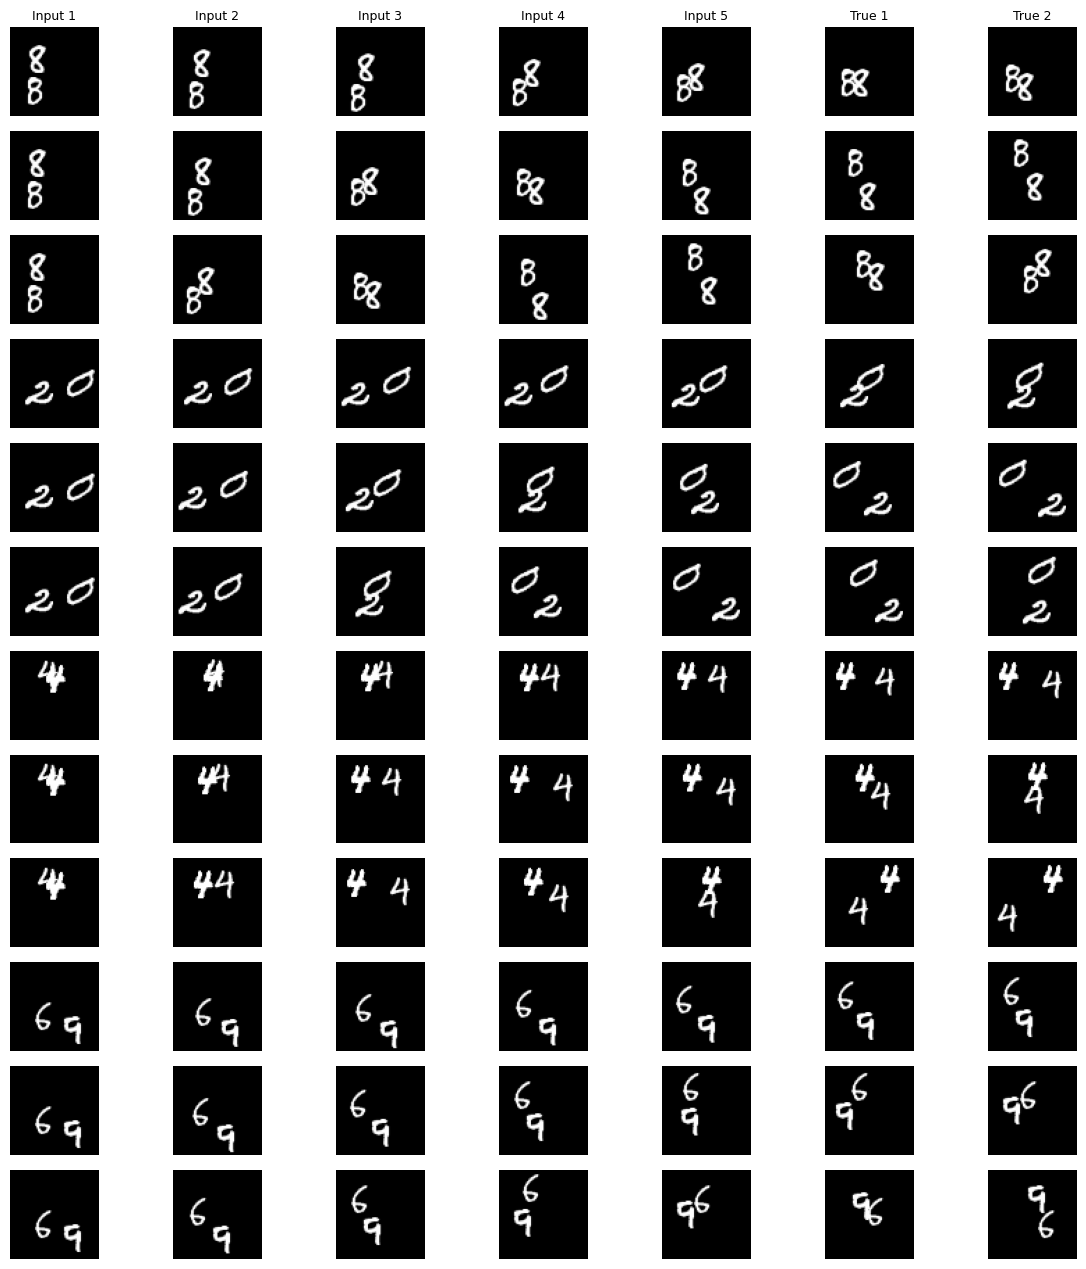

In [29]:
candidateids = [9004, 9005, 9006, 9007]

figure, axes = plt.subplots(
    len(candidateids) * 3,
    7,
    figsize=(12, len(candidateids) * 3.2),
)

for candidateindex, videoid in enumerate(candidateids):
    index = videoid - 9000

    video = convertvideos(
        testvideos[index:index + 1],
        scaledata,
    )

    for speedindex, speed in enumerate([1, 2, 3]):
        row = candidateindex * 3 + speedindex

        frameindices = [
            step * speed for step in range(5)
        ] + [
            (5 + step) * speed for step in range(2)
        ]

        for column, frameindex in enumerate(frameindices):
            axes[row, column].imshow(
                video[0, frameindex, 0].cpu(),
                cmap="gray",
                vmin=0,
                vmax=1,
            )

            axes[row, column].axis("off")

        axes[row, 0].set_ylabel(
            f"Video {videoid}\n{speed}x",
            fontsize=8,
        )

for column, title in enumerate([
    "Input 1", "Input 2", "Input 3",
    "Input 4", "Input 5",
    "True 1", "True 2",
]):
    axes[0, column].set_title(title, fontsize=9)

figure.tight_layout()
plt.show()

No Overlap Potential Candidate IDs: [9029, 9038, 9065, 9071, 9074, 9080, 9085, 9125, 9142, 9159, 9181, 9209]


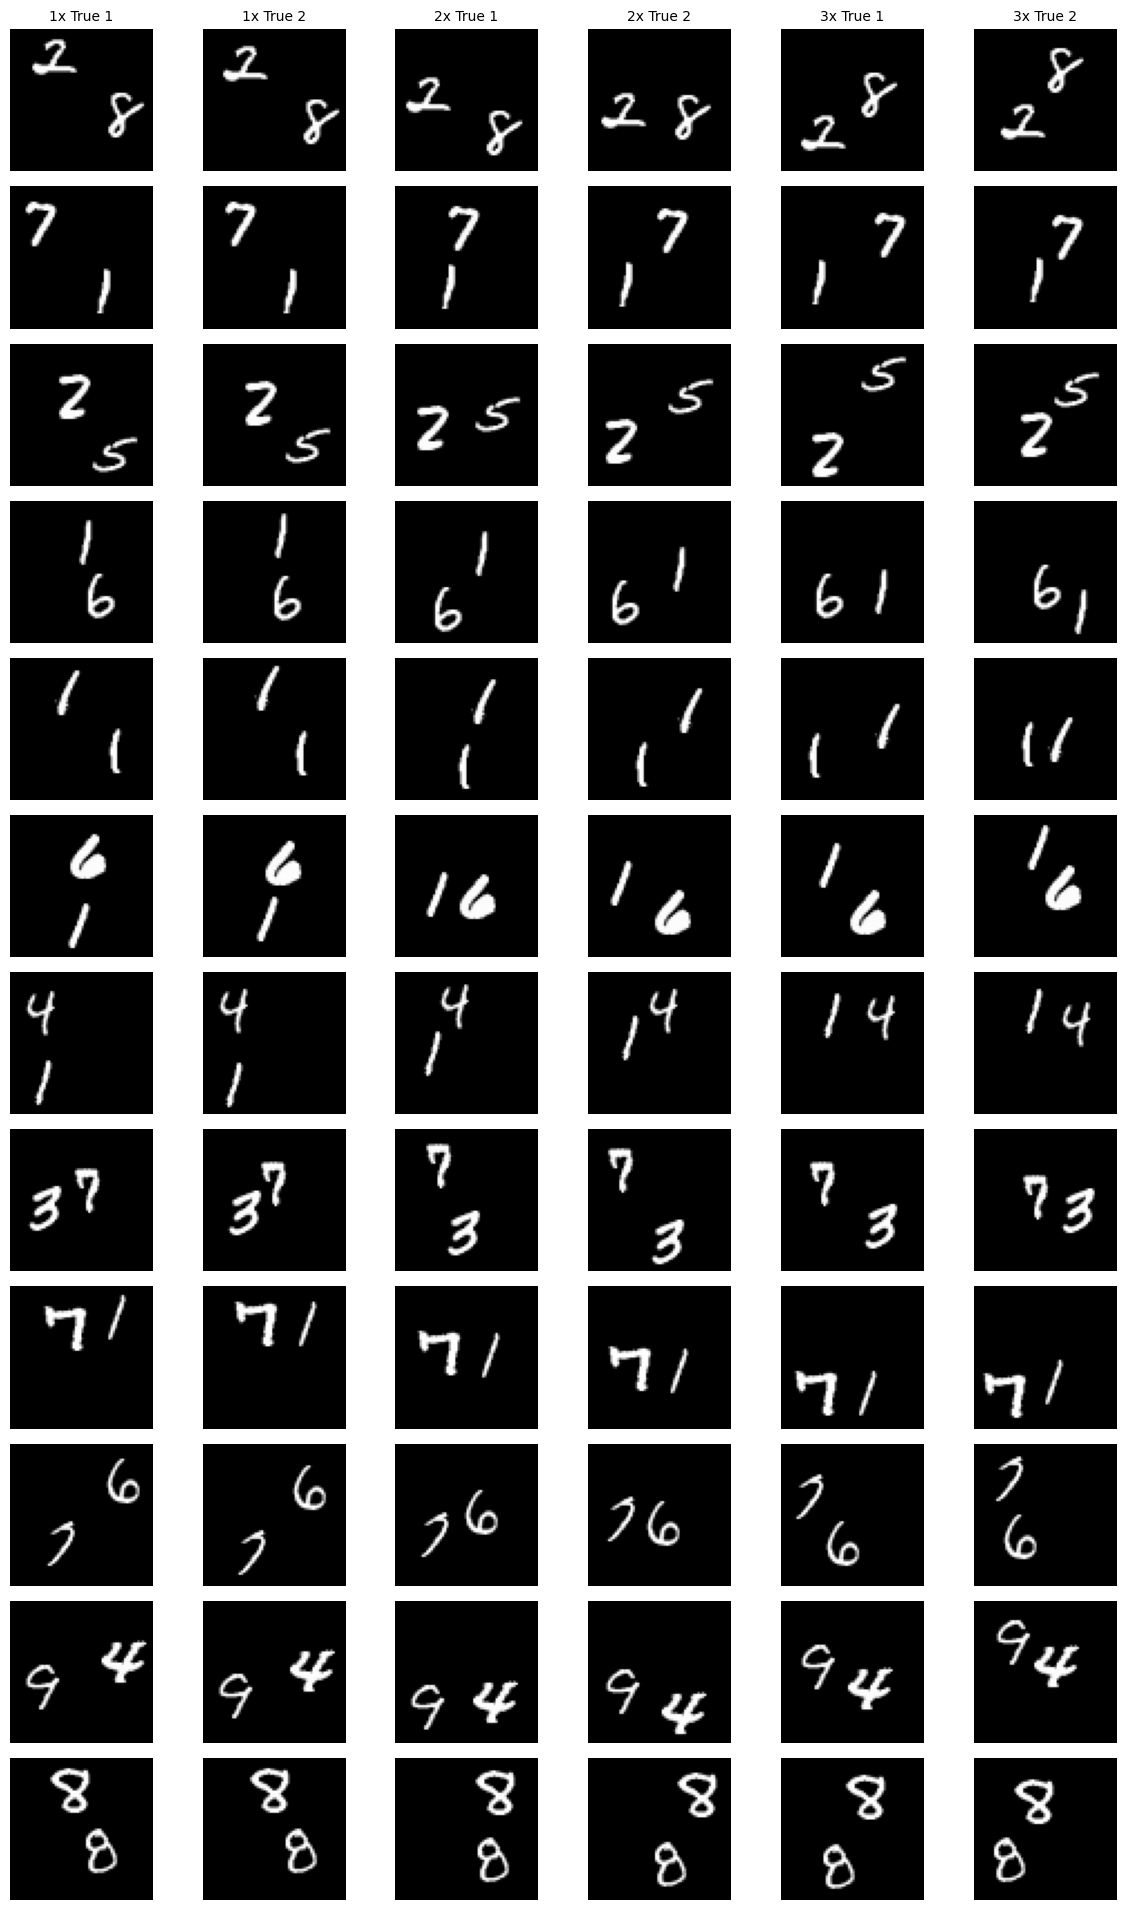

In [30]:
from scipy import ndimage
import matplotlib.pyplot as plt
import numpy as np

trueindices = [5, 6, 10, 12, 15, 18]
candidateids = []
threshold = 30 if scaledata else 0.12

for videoindex in range(len(testvideos)):
    validvideo = True

    for frameindex in trueindices:
        frame = testvideos[
            videoindex, frameindex, 0
        ].cpu().numpy()

        mask = frame > threshold

        labels, count = ndimage.label(
            mask,
            structure=np.ones((3, 3))
        )

        sizes = np.bincount(labels.ravel())[1:]
        components = np.where(sizes >= 20)[0] + 1

        if len(components) != 2:
            validvideo = False
            break

        first = labels == components[0]
        second = labels == components[1]

        distances = ndimage.distance_transform_edt(~first)
        minimumgap = distances[second].min()

        if minimumgap < 5:
            validvideo = False
            break

    if validvideo:
        candidateids.append(videoindex + 9000)

    if len(candidateids) == 12:
        break

print("No Overlap Potential Candidate IDs:", candidateids)

if not candidateids:
    print("No candidates found.")

else:
    figure, axes = plt.subplots(
        len(candidateids), 6,
        figsize=(12, len(candidateids) * 1.6),
        squeeze=False
    )

    for row, videoid in enumerate(candidateids):
        videoindex = videoid - 9000

        for column, frameindex in enumerate(trueindices):
            frame = testvideos[
                videoindex, frameindex, 0
            ].cpu().numpy()

            axes[row, column].imshow(
                frame, cmap="gray"
            )

            axes[row, column].axis("off")

            if column == 0:
                axes[row, column].set_ylabel(
                    str(videoid), rotation=0,
                    labelpad=25
                )

    for column, title in enumerate([
        "1x True 1", "1x True 2",
        "2x True 1", "2x True 2",
        "3x True 1", "3x True 2"
    ]):
        axes[0, column].set_title(title, fontsize=10)

    plt.tight_layout()
    plt.show()

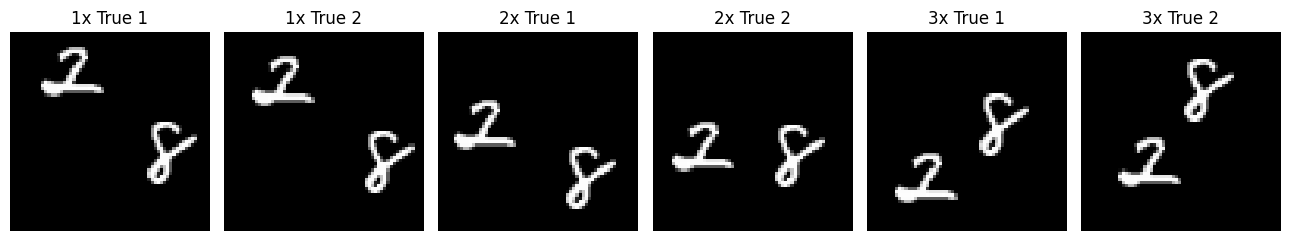

In [31]:
figure5id = 9029

video = convertvideos(
    testvideos[figure5id - 9000:figure5id - 8999],
    scaledata
)

trueindices = [5, 6, 10, 12, 15, 18]

figure, axes = plt.subplots(1, 6, figsize=(13, 3))

for index, frameindex in enumerate(trueindices):
    axes[index].imshow(
        video[0, frameindex, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[index].set_title(
        ["1x True 1", "1x True 2",
         "2x True 1", "2x True 2",
         "3x True 1", "3x True 2"][index]
    )

    axes[index].axis("off")

plt.tight_layout()
plt.show()

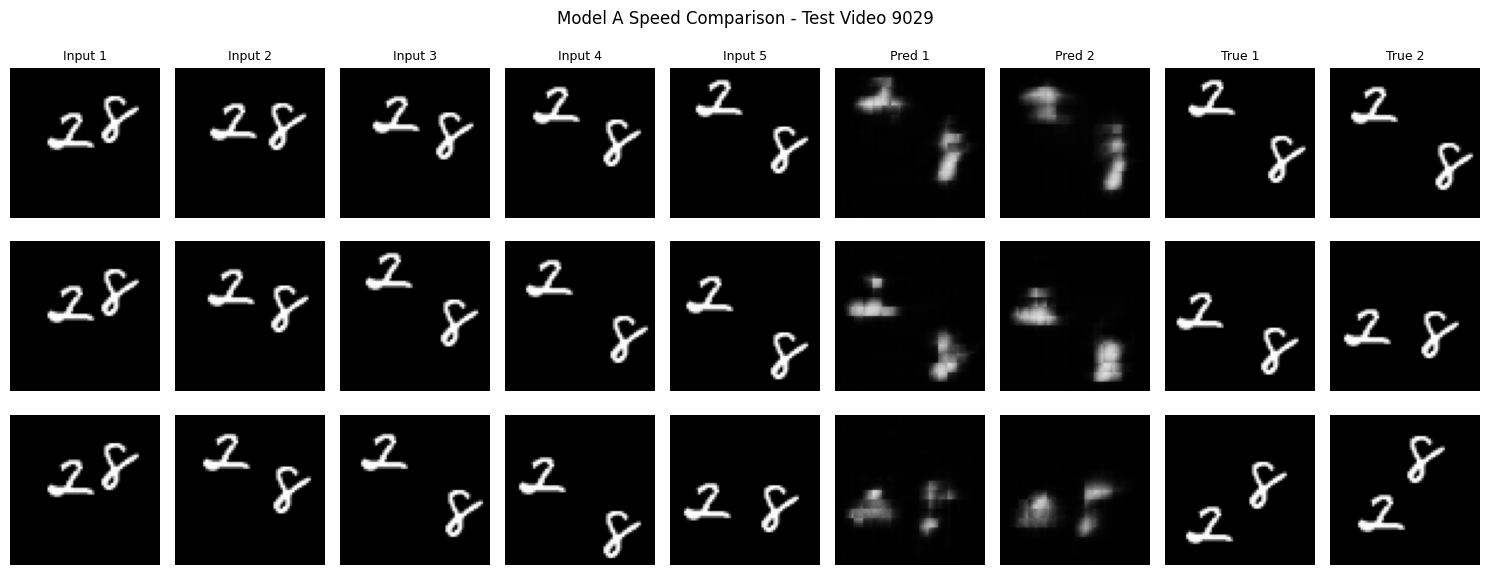

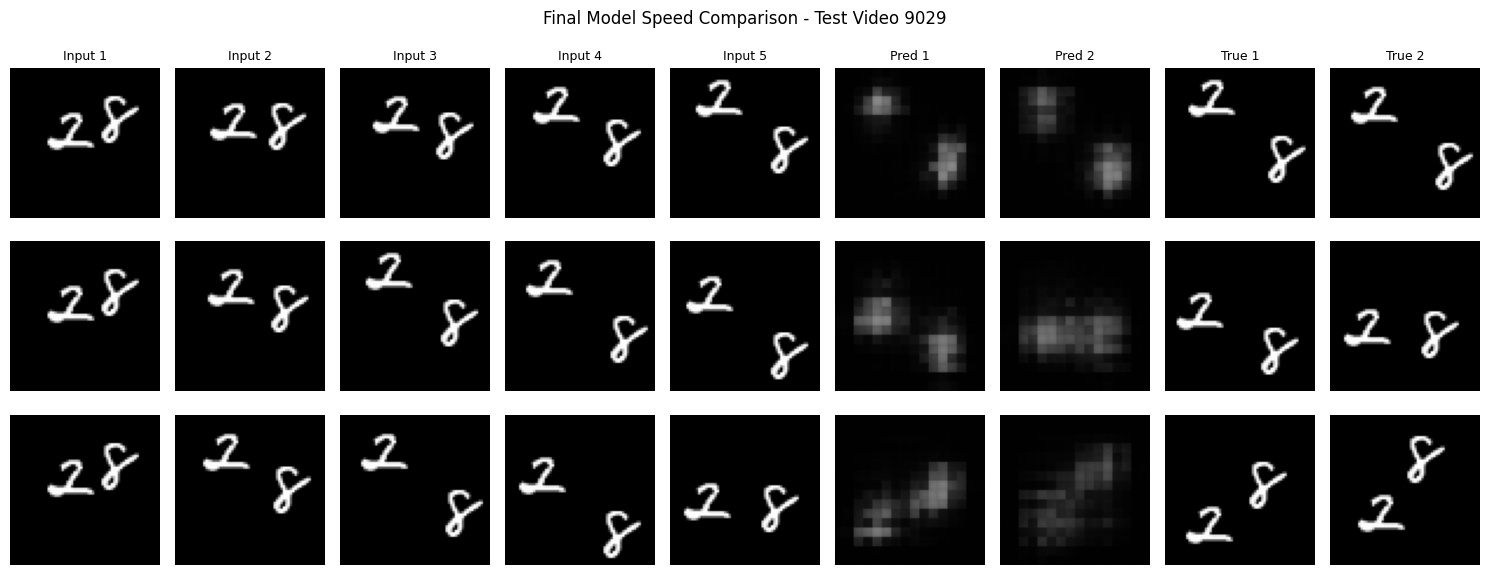

Figure 5 generated.
Figure 6b generated.
Selected testing video: 9029


In [33]:
import json
import matplotlib.pyplot as plt


def makespeedfigure(model, videoid, title, filename):
    videoindex = videoid - 9000

    video = convertvideos(
        testvideos[videoindex:videoindex + 1],
        scaledata
    )

    figure, axes = plt.subplots(
        3, 9,
        figsize=(15, 6)
    )

    model.eval()

    with torch.no_grad():
        for row, speed in enumerate([1, 2, 3]):
            inputindices = [
                step * speed
                for step in range(5)
            ]

            targetindices = [
                (5 + step) * speed
                for step in range(2)
            ]

            inputs = video[:, inputindices]
            targets = video[:, targetindices]

            predictions = model(inputs)[:, :2]

            frames = [
                inputs[0, :, 0].cpu(),
                predictions[0, :, 0].cpu(),
                targets[0, :, 0].cpu()
            ]

            for group, start in [
                (frames[0], 0),
                (frames[1], 5),
                (frames[2], 7)
            ]:
                for offset in range(len(group)):
                    axes[row, start + offset].imshow(
                        group[offset],
                        cmap="gray",
                        vmin=0,
                        vmax=1
                    )

                    axes[row, start + offset].axis("off")

            axes[row, 0].set_ylabel(f"{speed}x")

    titles = [
        "Input 1", "Input 2", "Input 3",
        "Input 4", "Input 5",
        "Pred 1", "Pred 2",
        "True 1", "True 2"
    ]

    for index, label in enumerate(titles):
        axes[0, index].set_title(label, fontsize=9)

    figure.suptitle(
        f"{title} - Test Video {videoid}"
    )

    plt.tight_layout()

    figure.savefig(
        finalpath / filename,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(figure)


checkpoint = torch.load(
    getmodelapath(0),
    map_location="cpu",
    weights_only=True
)

originalmodel = modela().to(device)

originalmodel.load_state_dict(
    checkpoint["modelstate"]
)

originalmodel.eval()


basemodel, checkpointd = loadtrainedmodel("d", 0)

finalmodel = symmetrisedmodel(
    basemodel
).to(device).eval()


makespeedfigure(
    originalmodel,
    figure5id,
    "Model A Speed Comparison",
    "figure5_modela_speedtests.png"
)

makespeedfigure(
    finalmodel,
    figure5id,
    "Final Model Speed Comparison",
    "figure6b_finalmodel_speedtests.png"
)


with open(
    finalpath / "figure5_selection.json",
    "w"
) as file:
    json.dump(
        {
            "testvideoid": figure5id,
            "verifiednonoverlap": True,
            "modelafigure": "figure5_modela_speedtests.png",
            "finalfigure": "figure6b_finalmodel_speedtests.png"
        },
        file,
        indent=2
    )


del originalmodel, basemodel, finalmodel
del checkpoint, checkpointd

if device.type == "cuda":
    torch.cuda.empty_cache()

print("Figure 5 generated.")
print("Figure 6b generated.")
print("Selected testing video:", figure5id)

In [34]:
import shutil
import zipfile

requiredfiles = [
    evaluationpath / "table6perseed.json",
    evaluationpath / "table6perseed.csv",
    evaluationpath / "table6summary.csv",
    finalpath / "figure5_selection.json",
    finalpath / "figure5_modela_speedtests.png",
    finalpath / "figure6b_finalmodel_speedtests.png"
]

selectedvideos = {
    "mirror": [9269, 9347],
    "rotation": [9733, 9883]
}

for transformname, videoids in selectedvideos.items():
    for rank, videoid in enumerate(videoids, start=1):
        filename = (
            f"figure6a_{transformname}_"
            f"rank{rank}_test{videoid}"
        )

        requiredfiles.append(
            finalpath / f"{filename}.png"
        )

        requiredfiles.append(
            finalpath / f"{filename}.gif"
        )


for filename in requiredfiles:
    if not filename.exists():
        raise FileNotFoundError(
            f"Missing file: {filename}"
        )


archivefile = shutil.make_archive(
    "/kaggle/working/bcd_final_results_bundle",
    "zip",
    root_dir="/kaggle/working",
    base_dir="bcd_outputs"
)

with zipfile.ZipFile(archivefile) as archive:
    if archive.testzip() is not None:
        raise RuntimeError("ZIP verification error")


print("Final archive:", archivefile)
print(
    "Archive size:",
    round(
        Path(archivefile).stat().st_size / (1024 ** 2),
        2
    ),
    "MB"
)

Final archive: /kaggle/working/bcd_final_results_bundle.zip
Archive size: 11.25 MB
